# Data Visualization Basics

Latihan membuat lima jenis grafik (histogram, bar chart, box plot, scatter plot, dan heatmap korelasi) dengan Matplotlib dan Seaborn, lalu membandingkan keduanya.

**Dataset:** Tips, bawaan Seaborn (`sns.load_dataset("tips")`), berisi 244 transaksi restoran dengan 7 kolom: `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, dan `size`.

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [20]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


### Gambaran Data

Dataset memiliki 244 baris tanpa data kosong. Kolom angka adalah `total_bill`, `tip`, dan `size`, sedangkan `sex`, `smoker`, `day`, dan `time` adalah kategori. Rata-rata total tagihan (19,79 dolar) lebih besar dari mediannya (17,80 dolar), yang menunjukkan adanya tagihan besar yang jarang terjadi.

In [21]:
urutan_hari = ["Thur", "Fri", "Sat", "Sun"]
sns.set_theme(style="whitegrid", font_scale=1.1)

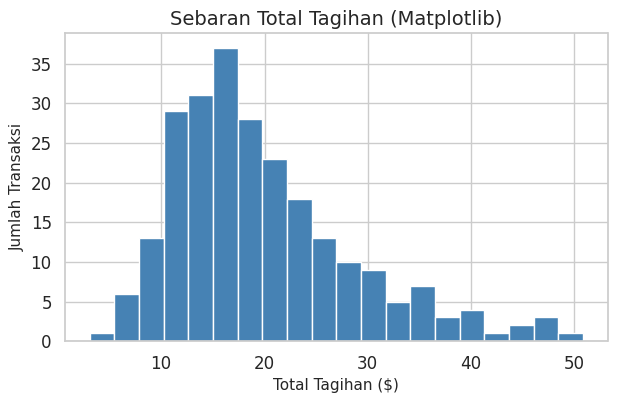

In [22]:
plt.figure(figsize=(7, 4))
plt.hist(df["total_bill"], bins=20, color="steelblue", edgecolor="white")
plt.title("Sebaran Total Tagihan (Matplotlib)", fontsize=14)
plt.xlabel("Total Tagihan ($)", fontsize=11)
plt.ylabel("Jumlah Transaksi", fontsize=11)
plt.show()

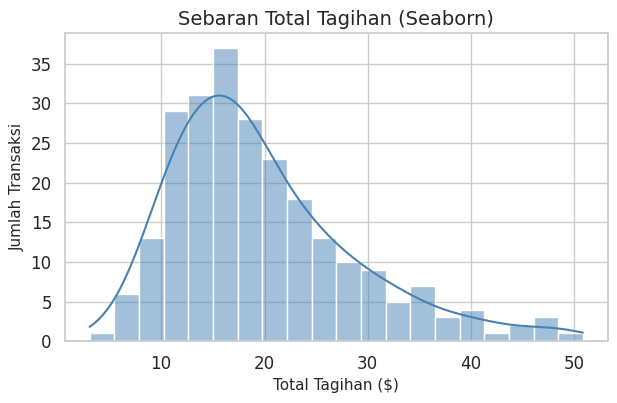

In [23]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="total_bill", bins=20, kde=True, color="steelblue")
plt.title("Sebaran Total Tagihan (Seaborn)", fontsize=14)
plt.xlabel("Total Tagihan ($)", fontsize=11)
plt.ylabel("Jumlah Transaksi", fontsize=11)
plt.show()

### Histogram: Sebaran Total Tagihan

Histogram menunjukkan bahwa sebagian besar tagihan berada di rentang sekitar 10 sampai 25 dolar, dengan puncak di sekitar 15 sampai 17 dolar. Sebaran condong ke kanan karena ada beberapa tagihan besar hingga sekitar 50 dolar.

**Perbandingan:** kedua library menghasilkan batang yang sama. Perbedaannya, Seaborn dapat menambahkan kurva kepadatan hanya dengan `kde=True`, sedangkan di Matplotlib hal itu membutuhkan langkah tambahan. Tampilan bawaan Seaborn juga lebih lembut karena batangnya sedikit transparan.

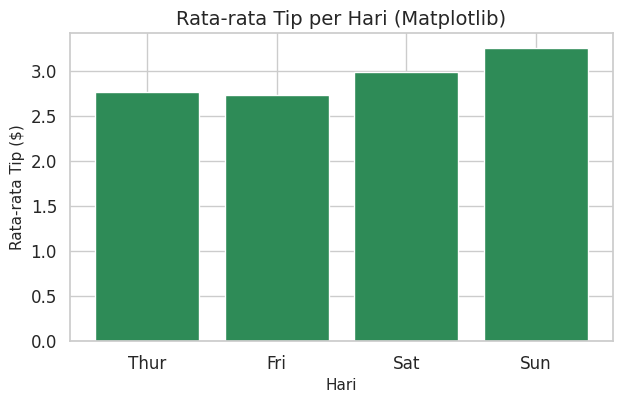

In [24]:
rata_tip = df.groupby("day", observed=True)["tip"].mean().reindex(urutan_hari)

plt.figure(figsize=(7, 4))
plt.bar(rata_tip.index.astype(str), rata_tip.values, color="seagreen")
plt.title("Rata-rata Tip per Hari (Matplotlib)", fontsize=14)
plt.xlabel("Hari", fontsize=11)
plt.ylabel("Rata-rata Tip ($)", fontsize=11)
plt.show()

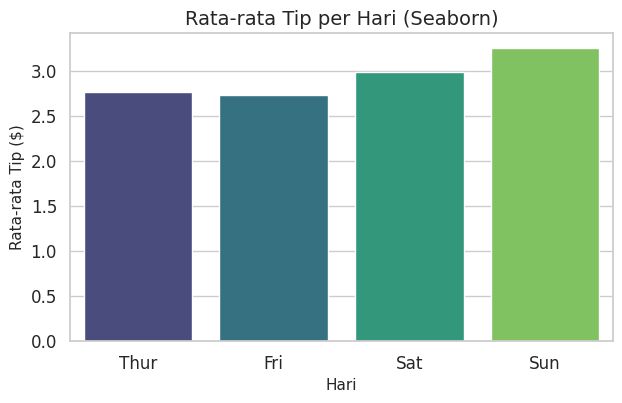

In [25]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="day", y="tip", order=urutan_hari,
            hue="day", palette="viridis", legend=False, errorbar=None)
plt.title("Rata-rata Tip per Hari (Seaborn)", fontsize=14)
plt.xlabel("Hari", fontsize=11)
plt.ylabel("Rata-rata Tip ($)", fontsize=11)
plt.show()

### Bar Chart: Rata-rata Tip per Hari

Rata-rata tip cenderung lebih tinggi pada akhir pekan. Minggu memiliki rata-rata tertinggi (sekitar 3,25 dolar), sedangkan Jumat terendah (sekitar 2,73 dolar). Kamis dan Jumat hampir sama.

**Perbandingan:** di Matplotlib, rata-rata per hari harus dihitung terlebih dahulu dengan `groupby`, lalu hasilnya dimasukkan ke `plt.bar`. Di Seaborn, `sns.barplot` menerima data mentah dan menghitung rata-ratanya sendiri. Seaborn juga dapat memberi warna berbeda untuk tiap batang dengan parameter `palette`.

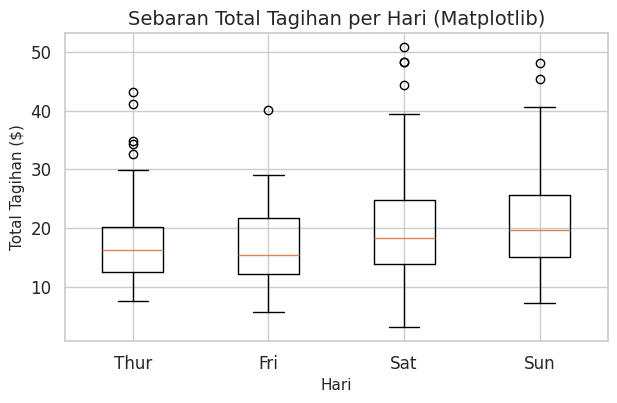

In [26]:
data_per_hari = [df.loc[df["day"] == h, "total_bill"] for h in urutan_hari]

plt.figure(figsize=(7, 4))
plt.boxplot(data_per_hari)
plt.xticks(range(1, 5), urutan_hari)
plt.title("Sebaran Total Tagihan per Hari (Matplotlib)", fontsize=14)
plt.xlabel("Hari", fontsize=11)
plt.ylabel("Total Tagihan ($)", fontsize=11)
plt.show()

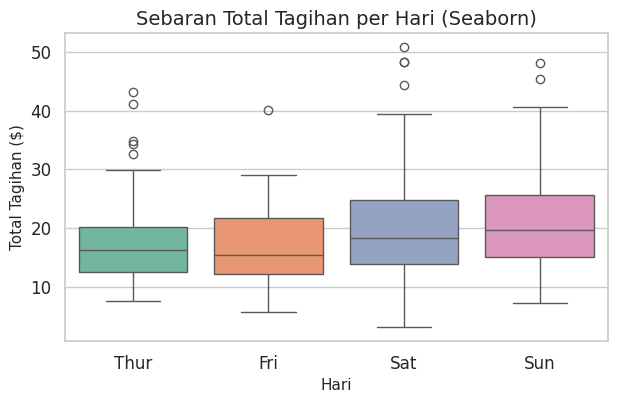

In [27]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="day", y="total_bill", order=urutan_hari,
            hue="day", palette="Set2", legend=False)
plt.title("Sebaran Total Tagihan per Hari (Seaborn)", fontsize=14)
plt.xlabel("Hari", fontsize=11)
plt.ylabel("Total Tagihan ($)", fontsize=11)
plt.show()

### Box Plot: Sebaran Total Tagihan per Hari

Median tagihan cenderung naik dari Jumat (sekitar 15 dolar) ke Minggu (sekitar 20 dolar), dan sebaran tagihan di akhir pekan lebih lebar. Semua hari memiliki pencilan di sisi atas, dengan tagihan tertinggi (sekitar 51 dolar) terjadi pada hari Sabtu.

**Perbandingan:** di Matplotlib, data harus dipisah per hari secara manual sebelum diberikan ke `plt.boxplot`, dan label hari diatur dengan `plt.xticks`. Di Seaborn, `sns.boxplot` langsung menerima kolom `day` dan `total_bill`, serta dapat memberi warna berbeda untuk tiap kotak dengan `palette`.

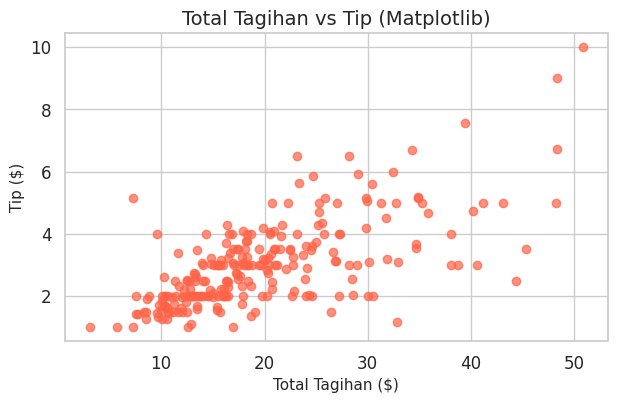

In [28]:
plt.figure(figsize=(7, 4))
plt.scatter(df["total_bill"], df["tip"], color="tomato", alpha=0.7)
plt.title("Total Tagihan vs Tip (Matplotlib)", fontsize=14)
plt.xlabel("Total Tagihan ($)", fontsize=11)
plt.ylabel("Tip ($)", fontsize=11)
plt.show()

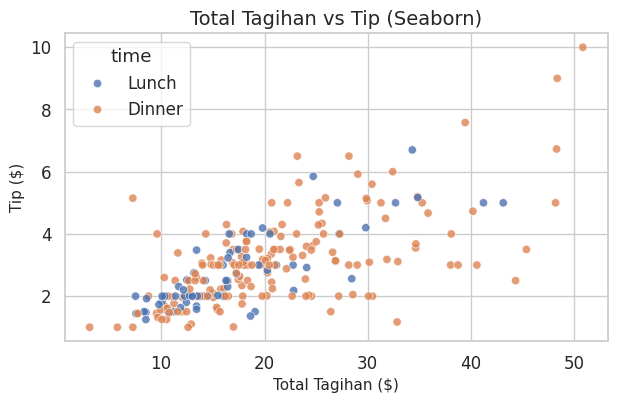

In [29]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", alpha=0.8)
plt.title("Total Tagihan vs Tip (Seaborn)", fontsize=14)
plt.xlabel("Total Tagihan ($)", fontsize=11)
plt.ylabel("Tip ($)", fontsize=11)
plt.show()

### Scatter Plot: Total Tagihan vs Tip

Scatter plot menunjukkan hubungan positif: makin besar total tagihan, tip cenderung makin besar. Sebaran titik melebar pada tagihan besar, sehingga hubungannya kurang rapat di sana. Terdapat satu titik yang menonjol, yaitu tagihan sekitar 50 dolar dengan tip 10 dolar. Pada versi Seaborn, transaksi Lunch tampak terkumpul di tagihan kecil sampai menengah, sedangkan Dinner tersebar di seluruh rentang. Hubungan ini bersifat pola, bukan bukti sebab-akibat.

**Perbandingan:** di Matplotlib, semua titik berwarna sama kecuali dibuat perulangan manual per kategori. Di Seaborn, parameter `hue="time"` otomatis mewarnai titik dan membuat legenda.

In [30]:
korelasi = df.corr(numeric_only=True)
korelasi

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


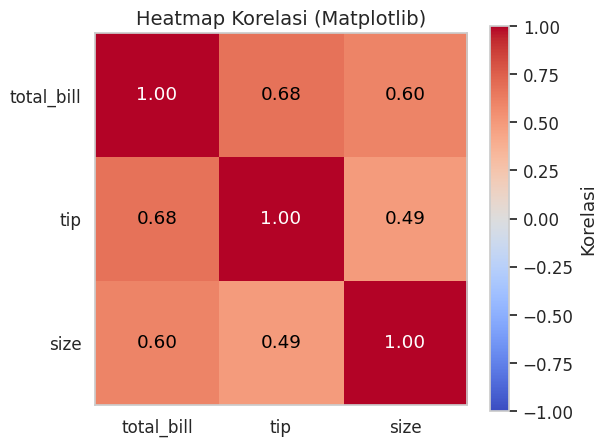

In [31]:
plt.figure(figsize=(6, 5))
plt.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Korelasi")
plt.grid(False)
plt.xticks(range(len(korelasi.columns)), korelasi.columns)
plt.yticks(range(len(korelasi.columns)), korelasi.columns)

for i in range(len(korelasi)):
    for j in range(len(korelasi)):
        nilai = korelasi.iloc[i, j]
        warna = "white" if abs(nilai) > 0.8 else "black"
        plt.text(j, i, f"{nilai:.2f}", ha="center", va="center", color=warna)

plt.title("Heatmap Korelasi (Matplotlib)", fontsize=14)
plt.show()

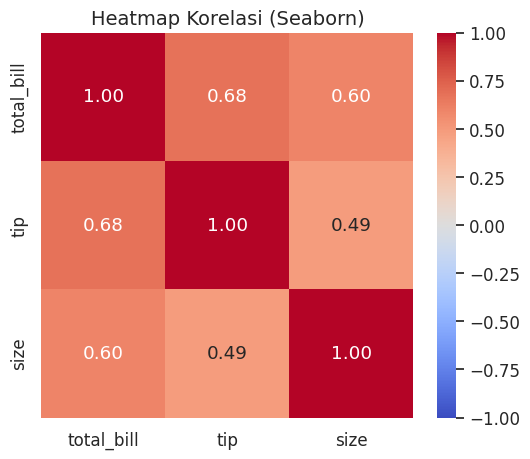

In [32]:
plt.figure(figsize=(6, 5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Heatmap Korelasi (Seaborn)", fontsize=14)
plt.savefig("heatmap_korelasi_seaborn.png", dpi=300, bbox_inches="tight")
plt.show()

### Heatmap Korelasi

Korelasi terkuat ada antara total tagihan dan tip (0,68), disusul total tagihan dan jumlah orang (0,60). Hubungan tip dan jumlah orang paling lemah (0,49). Seluruh korelasi bernilai positif, sejalan dengan pola pada scatter plot. Korelasi menunjukkan keterkaitan, bukan sebab-akibat.

**Perbandingan:** heatmap adalah grafik dengan perbedaan kode terbesar. Di Seaborn, `sns.heatmap` dengan `annot=True` otomatis menulis angka dan mengatur warna teksnya. Di Matplotlib, label sumbu, angka di tiap kotak, dan warna teks harus dibuat manual dengan perulangan.

## Perbandingan Matplotlib dan Seaborn

| Grafik | Matplotlib | Seaborn | Yang lebih mudah |
|---|---|---|---|
| Histogram | Batang saja, kurva kepadatan butuh langkah tambahan | Kurva ditambahkan dengan `kde=True` | Seaborn |
| Bar chart | Rata-rata dihitung manual dengan `groupby` | Menerima data mentah dan menghitung sendiri | Seaborn |
| Box plot | Data dipisah per hari secara manual | Cukup menyebut kolom | Seaborn |
| Scatter plot | Satu warna, kategori butuh perulangan | Warna per kategori dengan `hue` | Seaborn |
| Heatmap | Angka, label, dan warna teks dibuat manual | Satu baris dengan `annot=True` | Seaborn |

### Kapan memakai masing-masing

Seaborn lebih cepat untuk grafik statistik dari DataFrame karena menerima data mentah, menghitung ringkasan sendiri, dan mewarnai berdasarkan kategori dengan satu parameter. Matplotlib lebih panjang, tetapi memberi kontrol penuh atas setiap elemen dan dibutuhkan untuk grafik khusus. Karena Seaborn dibangun di atas Matplotlib, keduanya bisa dipakai bersamaan: Seaborn untuk membuat grafik, Matplotlib untuk menyempurnakan judul, label, dan menyimpan gambar.